# Scam victim prediction (v2)
Predicts whether a scam attempt succeeds (`engaged` = lost_money / shared_otp / clicked) or fails (ignored / replied). Change `CSV` below to use any file with the same columns.

In [1]:
CSV = "data/scam_encounters_india.csv"

In [2]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay

In [3]:
df = pd.read_csv(CSV)
FEATURES = ["channel", "claimed_sender", "asked_for", "urgency_pressure", "person_daily_upi_use"]
for col in FEATURES + ["engaged"]:
    df[col] = df[col].astype(str).str.strip().str.lower()
df = df.dropna(subset=["engaged"])
SUCCESS = ["lost_money", "shared_otp", "clicked"]
df["scam_worked"] = df["engaged"].isin(SUCCESS).astype(int)
print(df.shape)
print(df["scam_worked"].value_counts())
print(df["engaged"].value_counts())

(3005, 8)
scam_worked
0    1684
1    1321
Name: count, dtype: int64
engaged
lost_money    1246
replied        945
ignored        739
shared_otp      47
clicked         28
Name: count, dtype: int64


{'call': 1268, 'whatsapp': 1001, 'email': 579, 'sms': 157}
{'other': 1217, 'prize': 775, 'job': 646, 'bank_kyc': 225, 'refund': 90, 'family_emergency': 52}
{'money': 2037, 'nothing': 590, 'link': 119, 'otp': 112, 'qr_scan': 78, 'pin': 69}
{'no': 2559, 'yes': 446}
{'unknown': 3000, '4+ times': 3, '1-3 times': 2}


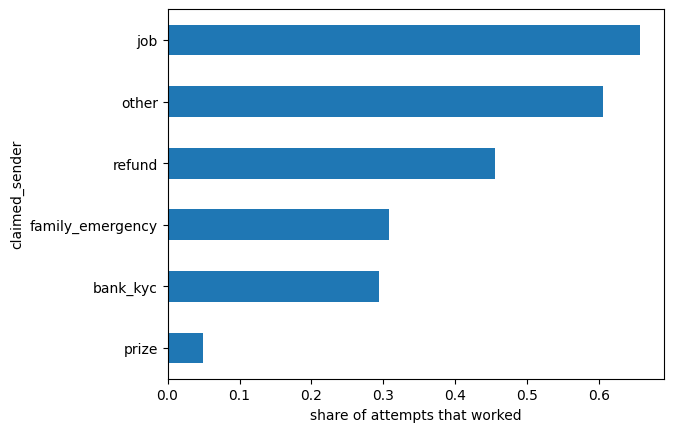

In [4]:
for col in FEATURES:
    print(df[col].value_counts().to_dict())
df.groupby("claimed_sender")["scam_worked"].mean().sort_values().plot.barh()
plt.xlabel("share of attempts that worked")
plt.show()

In [5]:
X = df[FEATURES]
y = df["scam_worked"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
enc = OneHotEncoder(handle_unknown="ignore")
Xtr = enc.fit_transform(X_train)
Xte = enc.transform(X_test)
print(len(y_train), len(y_test), y_test.sum(), Xtr.shape[1])

2404 601 264 21


In [6]:
def evaluate(name, model):
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    m = {"accuracy": round(accuracy_score(y_test, pred), 4),
         "precision": round(precision_score(y_test, pred, zero_division=0), 4),
         "recall": round(recall_score(y_test, pred), 4),
         "f1": round(f1_score(y_test, pred), 4),
         "roc_auc": round(roc_auc_score(y_test, proba), 4),
         "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}}
    print(name, m)
    return m, proba

lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42).fit(Xtr, y_train)
m_lr, p_lr = evaluate("LR", lr)

LR {'accuracy': 0.7687, 'precision': 0.6935, 'recall': 0.8485, 'f1': 0.7632, 'roc_auc': 0.8372, 'confusion': {'tn': 238, 'fp': 99, 'fn': 40, 'tp': 224}}


In [7]:
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", max_iter=300,
                    early_stopping=True, validation_fraction=0.1, random_state=42).fit(Xtr, y_train)
m_mlp, p_mlp = evaluate("MLP", mlp)
print(mlp.n_iter_)

MLP {'accuracy': 0.7903, 'precision': 0.727, 'recall': 0.8371, 'f1': 0.7782, 'roc_auc': 0.8482, 'confusion': {'tn': 254, 'fp': 83, 'fn': 43, 'tp': 221}}
29


               LR     MLP
accuracy   0.7687  0.7903
precision  0.6935   0.727
recall     0.8485  0.8371
f1         0.7632  0.7782
roc_auc    0.8372  0.8482


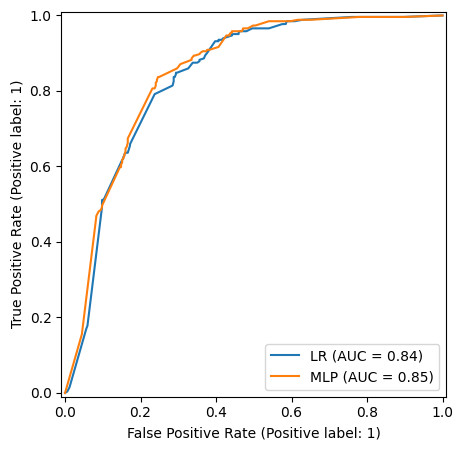

In [8]:
res = pd.DataFrame({"LR": m_lr, "MLP": m_mlp}).drop(index="confusion")
print(res)
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, p_lr, name="LR", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_mlp, name="MLP", ax=ax)
plt.show()

asked_for_nothing                -2.004385
claimed_sender_prize             -1.486355
channel_email                    -1.108095
urgency_pressure_yes             -0.713536
claimed_sender_bank_kyc          -0.638505
person_daily_upi_use_4+ times    -0.480241
person_daily_upi_use_1-3 times   -0.404545
asked_for_link                   -0.206864
dtype: float64
channel_sms                     0.132313
urgency_pressure_no             0.320748
person_daily_upi_use_unknown    0.491998
asked_for_qr_scan               0.582343
claimed_sender_other            0.677976
channel_whatsapp                0.758973
claimed_sender_job              1.039137
asked_for_otp                   1.417848
dtype: float64


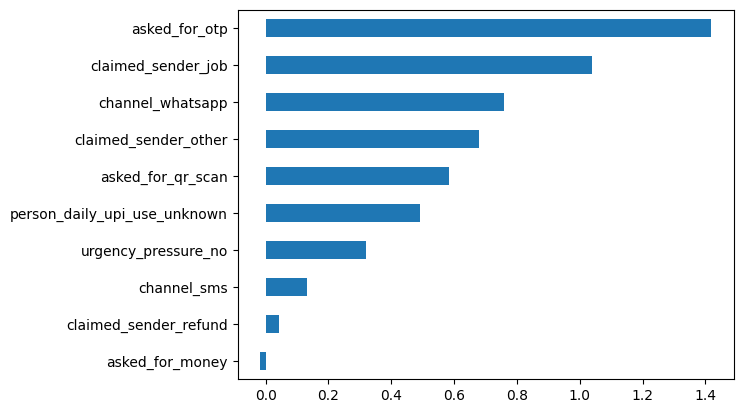

In [9]:
names = enc.get_feature_names_out()
coef = pd.Series(lr.coef_[0], index=names).sort_values()
print(coef.head(8))
print(coef.tail(8))
coef.tail(10).plot.barh()
plt.show()

In [10]:
os.makedirs("models_v2", exist_ok=True)
os.makedirs("results", exist_ok=True)
joblib.dump(lr, "models_v2/lr_model.joblib")
joblib.dump(mlp, "models_v2/mlp_model.joblib")
joblib.dump(enc, "models_v2/encoder.joblib")
joblib.dump(FEATURES, "models_v2/features.joblib")
out = {"csv": CSV, "rows": int(len(df)), "train_rows": int(len(y_train)), "test_rows": int(len(y_test)),
       "test_positive": int(y_test.sum()), "lr": m_lr, "mlp": m_mlp}
json.dump(out, open("results/metrics_v2.json", "w"), indent=2)
print(os.listdir("models_v2"))

['mlp_model.joblib', 'features.joblib', 'lr_model.joblib', 'encoder.joblib']


In [11]:
def check(channel, sender, asked, urgent, upi="unknown"):
    row = pd.DataFrame([[channel, sender, asked, urgent, upi]], columns=FEATURES)
    x = enc.transform(row)
    return round(float(lr.predict_proba(x)[0, 1]), 3), round(float(mlp.predict_proba(x)[0, 1]), 3)

print(check("call", "bank_kyc", "otp", "yes"))
print(check("whatsapp", "job", "money", "no"))
print(check("sms", "prize", "link", "yes"))
print(check("email", "refund", "nothing", "no"))

(0.41, 0.508)
(0.864, 0.833)
(0.074, 0.132)
(0.047, 0.062)
